In [4]:
import csv
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

ROOT = Path.cwd().resolve()
for _ in range(3):
    if (ROOT / "configs" / "base_akf.yaml").is_file():
        break
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from tracking.ssm.base_akf.model import SSM
from tracking.ssm.base_akf.track import track

GAME, CLIP = "game1", "Clip1"
START, COUNT = "0138.jpg", 12

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())

VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


clip = load_clip(GAME, CLIP)
filt = SSM(cfg["tracker"])
steps = track(
    filt,
    [frame["xy"] for frame in clip],
    gate_sigma=float(cfg["tracker"]["gate_sigma"]),
)
start = next(i for i, frame in enumerate(clip) if frame["file"] == START)
window = range(start, start + COUNT)

print(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[start + COUNT - 1]['file']}")
for i in window:
    frame, step = clip[i], steps[i]
    xy = frame["xy"]
    if step is None or step["pred"] is None:
        print(f"{frame['file']}  init / coast")
        continue
    x0, y0, x1, y1 = step["box"]
    err = float(np.hypot(*(step["pred"] - xy))) if xy is not None else float("nan")
    used = step["z"] is not None
    print(
        f"{frame['file']}  {MOVEMENT[frame['status']]:8}  "
        f"{VISIBILITY[frame['visibility']]:12}  "
        f"pred_err={err:5.1f}  box={x1 - x0:5.1f}  used={used}"
    )


game1/Clip1  0138.jpg → 0149.jpg
0138.jpg  flying    visible       pred_err=  8.0  box= 65.4  used=True
0139.jpg  flying    visible       pred_err=  8.7  box= 65.3  used=True
0140.jpg  flying    visible       pred_err=  7.4  box= 65.3  used=True
0141.jpg  hit       visible       pred_err= 46.7  box= 65.3  used=False
0142.jpg  hit       visible       pred_err=101.9  box=180.7  used=False
0143.jpg  flying    visible       pred_err=142.9  box=256.1  used=False
0144.jpg  flying    visible       pred_err=184.1  box=324.4  used=False
0145.jpg  flying    visible       pred_err=216.9  box=393.4  used=False
0146.jpg  flying    visible       pred_err=245.4  box=468.2  used=False
0147.jpg  flying    hard to see   pred_err=268.2  box=552.9  used=True
0148.jpg  flying    visible       pred_err= 13.8  box=156.7  used=True
0149.jpg  flying    visible       pred_err=  4.9  box=127.9  used=True


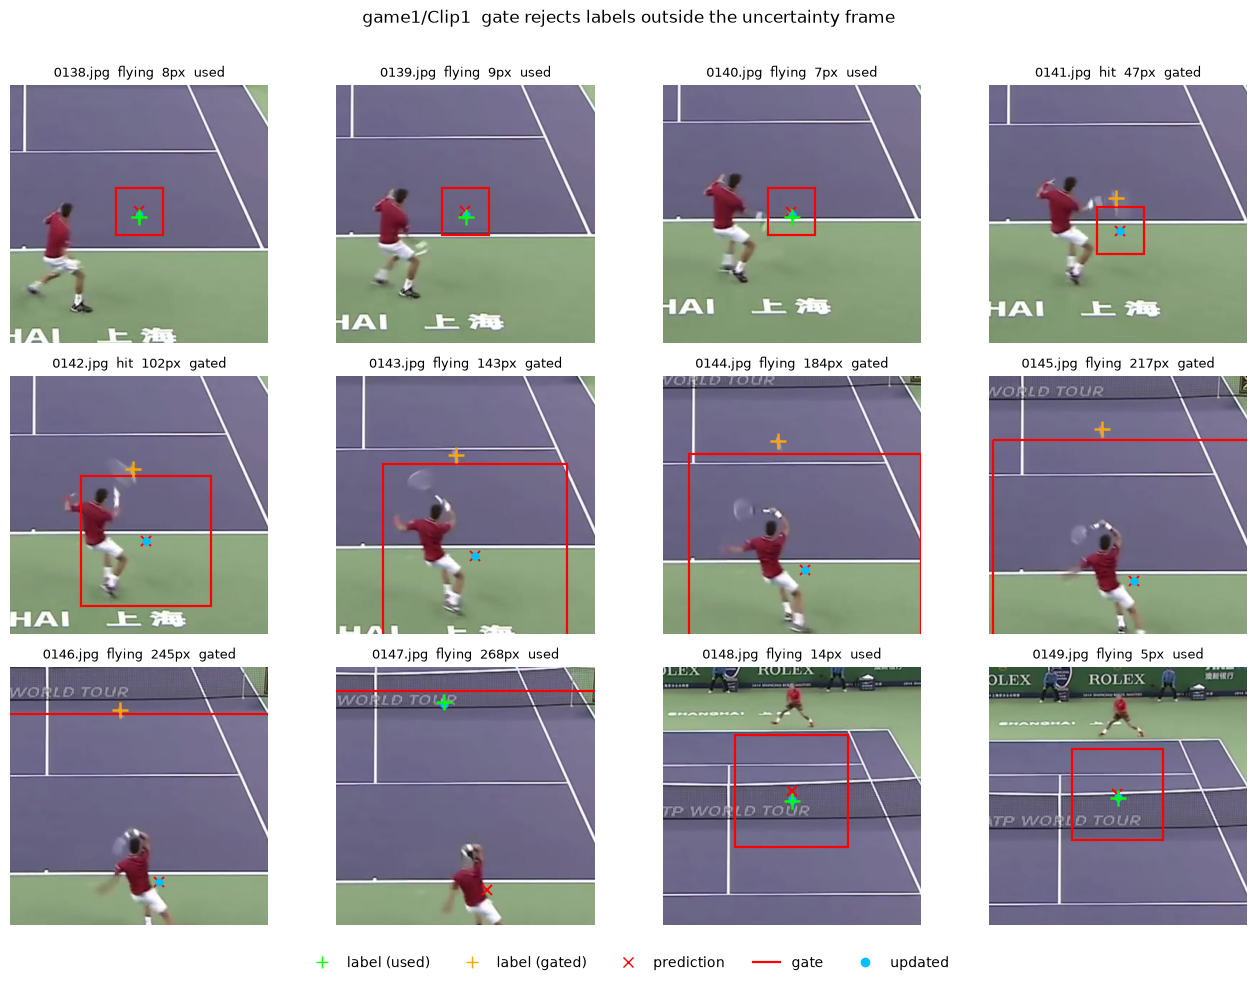

In [5]:
ncols = 4
half = 180
nrows = int(np.ceil(COUNT / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.3 * nrows))
for ax, i in zip(np.atleast_1d(axes).ravel(), window):
    frame, step = clip[i], steps[i]
    bgr = cv2.imread(str(frame["path"]), cv2.IMREAD_COLOR)
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    x0, y0, x1, y1 = step["box"]
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", lw=1.6))
    if step["pred"] is not None:
        ax.plot(*step["pred"], "x", color="red", ms=7, mew=1.4)
    ax.plot(*step["post"], "o", color="deepskyblue", ms=5)
    xy = frame["xy"]
    if xy is not None:
        color = "lime" if step["z"] is not None else "orange"
        ax.plot(*xy, "+", color=color, ms=11, mew=1.8)
        center = xy if step["pred"] is None else 0.5 * (step["pred"] + xy)
    else:
        center = step["post"]
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] + half, center[1] - half)
    err = (
        float(np.hypot(*(step["pred"] - xy)))
        if step["pred"] is not None and xy is not None
        else np.nan
    )
    title = frame["file"]
    if np.isfinite(err):
        tag = "used" if step["z"] is not None else "gated"
        title += f"  {MOVEMENT[frame['status']]}  {err:.0f}px  {tag}"
    ax.set_title(title, fontsize=9)
    ax.axis("off")

for ax in np.atleast_1d(axes).ravel()[COUNT:]:
    ax.axis("off")

fig.legend(
    handles=[
        Line2D([0], [0], marker="+", color="lime", lw=0, ms=8, label="label (used)"),
        Line2D([0], [0], marker="+", color="orange", lw=0, ms=8, label="label (gated)"),
        Line2D([0], [0], marker="x", color="red", lw=0, ms=7, label="prediction"),
        Line2D([0], [0], color="red", lw=1.6, label="gate"),
        Line2D([0], [0], marker="o", color="deepskyblue", lw=0, ms=6, label="updated"),
    ],
    loc="lower center",
    ncol=5,
    frameon=False,
)
fig.suptitle(f"{GAME}/{CLIP}  gate rejects labels outside the uncertainty frame", fontsize=12)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()


In [3]:
misses = gated = 0
errs, used, visibility, movement = [], [], [], []
for game in cfg["splits"]["test"]:
    game_dir = Path(cfg["paths"]["dataset"]) / game
    for clip_dir in sorted(p for p in game_dir.iterdir() if p.is_dir()):
        frames = load_clip(game, clip_dir.name)
        steps = track(
            SSM(cfg["tracker"]),
            [frame["xy"] for frame in frames],
            gate_sigma=float(cfg["tracker"]["gate_sigma"]),
        )
        for frame, step in zip(frames, steps):
            xy = frame["xy"]
            if step is None or step["pred"] is None:
                if frame["visibility"] == 0:
                    misses += 1
                continue
            if xy is None:
                misses += 1
                continue
            errs.append(float(np.hypot(*(step["pred"] - xy))))
            used.append(step["z"] is not None)
            visibility.append(frame["visibility"])
            movement.append(frame["status"])
            if step["z"] is None:
                gated += 1

errs = np.asarray(errs)
used = np.asarray(used)
visibility = np.asarray(visibility)
movement = np.asarray(movement)


def show_group(name: str, mask: np.ndarray) -> None:
    count = int(mask.sum())
    if count == 0:
        return
    print(
        f"{name:16}  n={count:5d}  "
        f"dist={errs[mask].mean():6.1f}  "
        f"used={used[mask].mean():.3f}"
    )


print(f"test  n={len(errs)}  dist = prediction error (px)  used = fraction accepted by gate")
show_group("all", np.ones(len(errs), dtype=bool))
print("movement")
for code, name in MOVEMENT.items():
    show_group(f"  {name}", movement == code)
print("obscurity")
print(f"{'  not in frame':16}  n={misses:5d}  coast, no label")
print(f"{'  gated out':16}  n={gated:5d}  label outside uncertainty frame")
for code, name in VISIBILITY.items():
    if code == 0:
        continue
    show_group(f"  {name}", visibility == code)


test  n=2070  dist = prediction error (px)  used = fraction accepted by gate
all               n= 2070  dist=   9.4  used=0.974
movement
  flying          n= 1964  dist=   8.9  used=0.982
  hit             n=   48  dist=  25.2  used=0.667
  bouncing        n=   58  dist=  12.7  used=0.983
obscurity
  not in frame    n=   62  coast, no label
  gated out       n=   53  label outside uncertainty frame
  visible         n= 1885  dist=   9.7  used=0.973
  hard to see     n=  184  dist=   6.6  used=0.984
  occluded        n=    1  dist=   1.7  used=1.000
